# CsI(Tl)–SiPM：电荷/基线条件化与后脉冲、恢复时间的原生对照

2026-10-30。承接[文献检索](codex_0001_csi_pid_bandwidth_literature_web.ipynb)与[平均波形/PID联合约束](codex_0001_csi_joint_constraints.ipynb)。本轮把文献建议变成两项可检查的诊断：

1. 在同一电荷区间内，箱内电荷分布和基线状态差异是否改变 PID 带宽结论？
2. 原生 SiPM 后脉冲或像元恢复时间能否提供所缺的波动，同时维持波形中心、均 ADC 和短尺度起伏？

本轮只用已有实测波形和已保存的 Geant4 光子历史。12 组 C++ 响应重放共 192000 条记录，但只有 **32000 个重复使用的母事件，新增独立输运母事件为 0**。以前称为验证的 MC 现在已用于诊断探索，不能继续称为本轮独立验证。
实测 first60 参与过校准；middle20/last20 也已多次探索，只作内部检查。没有本轮新增实验，没有实验粒子真值；²⁴¹Am 包含 α、γ 和衰变电子。


In [1]:
from pathlib import Path
import json,sys
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/conditional_response_20261030'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def f(x,places=3):return '不可估计' if x is None else f'{x:.{places}f}'
def ci(r):return '不可估计' if r['CI95'] is None else '['+', '.join(f(x) for x in r['CI95'])+']'
def nums(x):return ' / '.join(f(v) for v in x)
p=read(OUT/'protocol.json');c=read(OUT/'conditional.json');m=read(OUT/'mechanisms.json')
s=read(OUT/'supplement.json');decision=read(OUT/'decision.json')
print('Python / NumPy:',sys.version.split()[0],np.__version__)
print('原生重放记录:',p['replay_entries'],'不同原母事件:',p['unique_reused_mothers'],'新增独立母事件:',p['new_independent_mothers'])
display(Markdown(decision['conclusion_zh']))

Python / NumPy: 3.13.5 2.5.4
原生重放记录: 192000 不同原母事件: 32000 新增独立母事件: 0


**本轮未找到可直接替代经验信号残差的后脉冲或恢复时间方案，默认配置保持不变。**

Am 后段按箱内电荷两分匹配后，平均时间宽度比为 **0.917**，中心仍为 **+7.26 ns**。匹配造成的宽度比变化区间包含0；再同时匹配基线RMS时有空单元，无法可靠估计，不能据此归因于基线噪声。

固定同一批母事件和原Q时，原经验残差的平均时间宽度是关闭残差后的 **2.36 倍**；15%／300 ns后脉冲压力对照仅为 **1.036 倍**，却把中心推迟 **34.96 ns**。这是本次固定光学/读出下的机制敏感性结果，不是对所有后脉冲模型的排除，也没有测出真实器件的AP概率。

## 1. 固定分析定义与对照参数

装置假设沿用上轮：10×10×10 mm³ CsI(Tl)、PTFE 包裹、5 μm Mylar、S13361-3050 系列多单元求和、无前放。模拟中的16单元阵列、名义 PDE=0.3、增益1.7×10⁶和源距仍是条件假设；实际求和通道数、电路和温度信息不完整。

PID 用原定义：前128样点估计基线，2 ns采样，整数锚点 floor(t₁₀)+1，长门−40至3000 ns、短门−40至500 ns，以及冻结 PCA。平均时间分数存为负微秒，以下差值已换为正常时间方向的 ns。
共同 Q 区间分为原来的6箱；Co用全部6箱，Am只用前3箱。宽度为各箱 IQR 的平方平均再开方，各原箱等权。实验主带诊断沿用 QDC=0.4 分界，不用它宣称实验 α/γ 真值。

下表中的 AP 概率是代码中每次已接受雪崩的**提议概率参数**，延迟是指数分布均值；还会受恢复程度和次级接受过程影响，因此它不等于最终后脉冲占比。
5%、15%、60/300 ns和恢复60 ns是预设敏感性/压力对照，**不是从文献套来的本器件实测数值**。原名义恢复时间为29 ns。


In [2]:
rows=[]
for key,e in p['entries'].items():
    cfg=read(PROJECT/e['config']);z=cfg['sipm']['sensor'];r=read(OUT/'extraction'/f'{key}.json')
    v=read((PROJECT/e['path']).with_name(Path(e['path']).stem+'_validation.json'))
    rows.append([e['source'],e['variant'],z['afterpulse_probability'],z['afterpulse_delay_ns'],z['recovery_ns'],
        f(cfg['signal_dependent_noise']['variance_per_signal_adc']),e['events'],r['n_common'],r['gained'],r['lost'],v['passed']])
display(Markdown(table(['源','对照','AP提议概率','AP延迟/ns','恢复/ns','经验信号残差强度','母记录数','重新筛选共同Q数','进入/条','离开/条','物理检查'],rows)))
print('共同Q边界/ADC·sample:',p['q_edges'])
print('支持箱，0起算:',p['support_bins'])

共同Q边界/ADC·sample: [201824.1125, 237975.62708333333, 274127.14166666666, 310278.65625, 346430.17083333334, 382581.6854166667, 418733.2]
支持箱，0起算: {'Co60': [0, 1, 2, 3, 4, 5], 'Am241': [0, 1, 2]}


|源|对照|AP提议概率|AP延迟/ns|恢复/ns|经验信号残差强度|母记录数|重新筛选共同Q数|进入/条|离开/条|物理检查|
|---|---|---|---|---|---|---|---|---|---|---|
|Co60|identity|0.0|60.0|29.0|0.487|8000|276|0|0|True|
|Co60|no_signal_residual|0.0|60.0|29.0|0.000|8000|274|2|4|True|
|Co60|ap05_60ns|0.05|60.0|29.0|0.000|8000|269|5|12|True|
|Co60|ap05_300ns|0.05|300.0|29.0|0.000|8000|264|7|19|True|
|Co60|ap15_300ns|0.15|300.0|29.0|0.000|8000|238|32|70|True|
|Co60|recovery60ns|0.0|60.0|60.0|0.000|8000|274|2|4|True|
|Am241|identity|0.0|60.0|29.0|2.896|24000|194|0|0|True|
|Am241|no_signal_residual|0.0|60.0|29.0|0.000|24000|195|3|2|True|
|Am241|ap05_60ns|0.05|60.0|29.0|0.000|24000|198|5|1|True|
|Am241|ap05_300ns|0.05|300.0|29.0|0.000|24000|201|7|0|True|
|Am241|ap15_300ns|0.15|300.0|29.0|0.000|24000|209|15|0|True|
|Am241|recovery60ns|0.0|60.0|60.0|0.000|24000|195|3|2|True|

原参数 identity 保留上轮全部设置；其余五组首先关闭经验信号期残差，再单独改变相应原生机制，避免把同一缺失波动重复补两次。
每组保留原母事件/种子及到达光子的时间、位置、波长历史，固定光学、PDE、增益、SPE及被动读出。关闭经验残差只用于消融；不是声称实际器件没有这类起伏。
恢复60 ns这组只改模型中的像元恢复过程，SPE下降时间仍固定29 ns；这是一项局部灵敏度检查，不表示实际器件的恢复、增益和脉冲响应可以彼此独立调整。

空间串扰继续为0：现有阵列展开映射没有保存二维像元邻接关系，代码明确禁止在这种映射下开启空间串扰。暗计数本轮同样固定0，未由本次对照排除其实际存在。
原生后脉冲与恢复变化可能改变后续一次光子雪崩是否被接受；共用光子历史不意味着每组有完全相同的雪崩。
新增 `ResponseDiagnostics` 独立 ROOT 树保存实际一次/AP/暗/串扰计数及恢复程度，不改变 Events 格式或随机数序列。原参数重放要求全部32000个母事件的 ADC 和雪崩时间/电荷逐点完全相同。


## 2. 箱内分布匹配：固定 first60 目标

在每个原 Q 箱内，用 first60 实验数据冻结中位数/四分位数，比较四种权重：原箱等权、箱内 Q 两分、Q 四分、Q 两分×基线 RMS 两分。
每个组合单元的权重为“first60目标质量/该样本单元事件数”；不删事件、不截权、不对空单元外推。缺少正目标质量的单元时，该项整体不可估计。
因此匹配后的统计量仍是**原 Q 箱内的加权分布**，不是更窄的积分窗口，也不是消除了所有电荷依赖。

加权分位数使用端点归一化的权重中点 CDF，等权时与 NumPy type7 分位数一致。bootstrap 的整数重复次数先展开，再做匹配。
原生 MC 用512次完整原母事件重采样；实验用原始事件索引的连续块重采样，块长64和128都报告。first60切点、目标质量、旧拟合及装置假设固定，区间没有包含这些量的不确定性。
重采样出现空单元则记无效；至少128个有效抽样才列区间，且区间只基于有效抽样。有效次数少于512提示稀疏支持限制，不能解释为无偏的状态校正。


|源/后段|权重|MC−实测平均时间/ns|块64区间/ns|QDC/时间/PCA宽度比|时间宽度比区间64|区间128|有效抽样/512|
|---|---|---|---|---|---|---|---|
|Co60|original|-0.160|[-2.402, 2.085]|1.030 / 0.927 / 1.037|[0.814, 1.200]|[0.821, 1.190]|512|
|Co60|q2|-0.498|[-2.676, 1.691]|0.997 / 0.940 / 1.015|[0.798, 1.207]|[0.823, 1.188]|512|
|Co60|q4|-0.416|[-2.683, 2.196]|1.015 / 0.969 / 1.050|[0.765, 1.202]|[0.800, 1.213]|438|
|Co60|q2r2|0.147|[-1.925, 2.313]|0.936 / 0.935 / 0.971|[0.807, 1.186]|[0.803, 1.149]|456|
|Am241|original|7.216|[1.144, 13.421]|1.098 / 0.887 / 1.125|[0.686, 1.091]|[0.687, 1.040]|512|
|Am241|q2|7.258|[0.783, 14.200]|1.058 / 0.917 / 1.096|[0.705, 1.117]|[0.699, 1.087]|512|
|Am241|q4|7.935|[0.429, 15.376]|1.051 / 0.909 / 1.080|[0.660, 1.106]|[0.657, 1.078]|498|
|Am241|q2r2|不可估计|不可估计|不可估计 / 不可估计 / 不可估计|不可估计|不可估计|0|

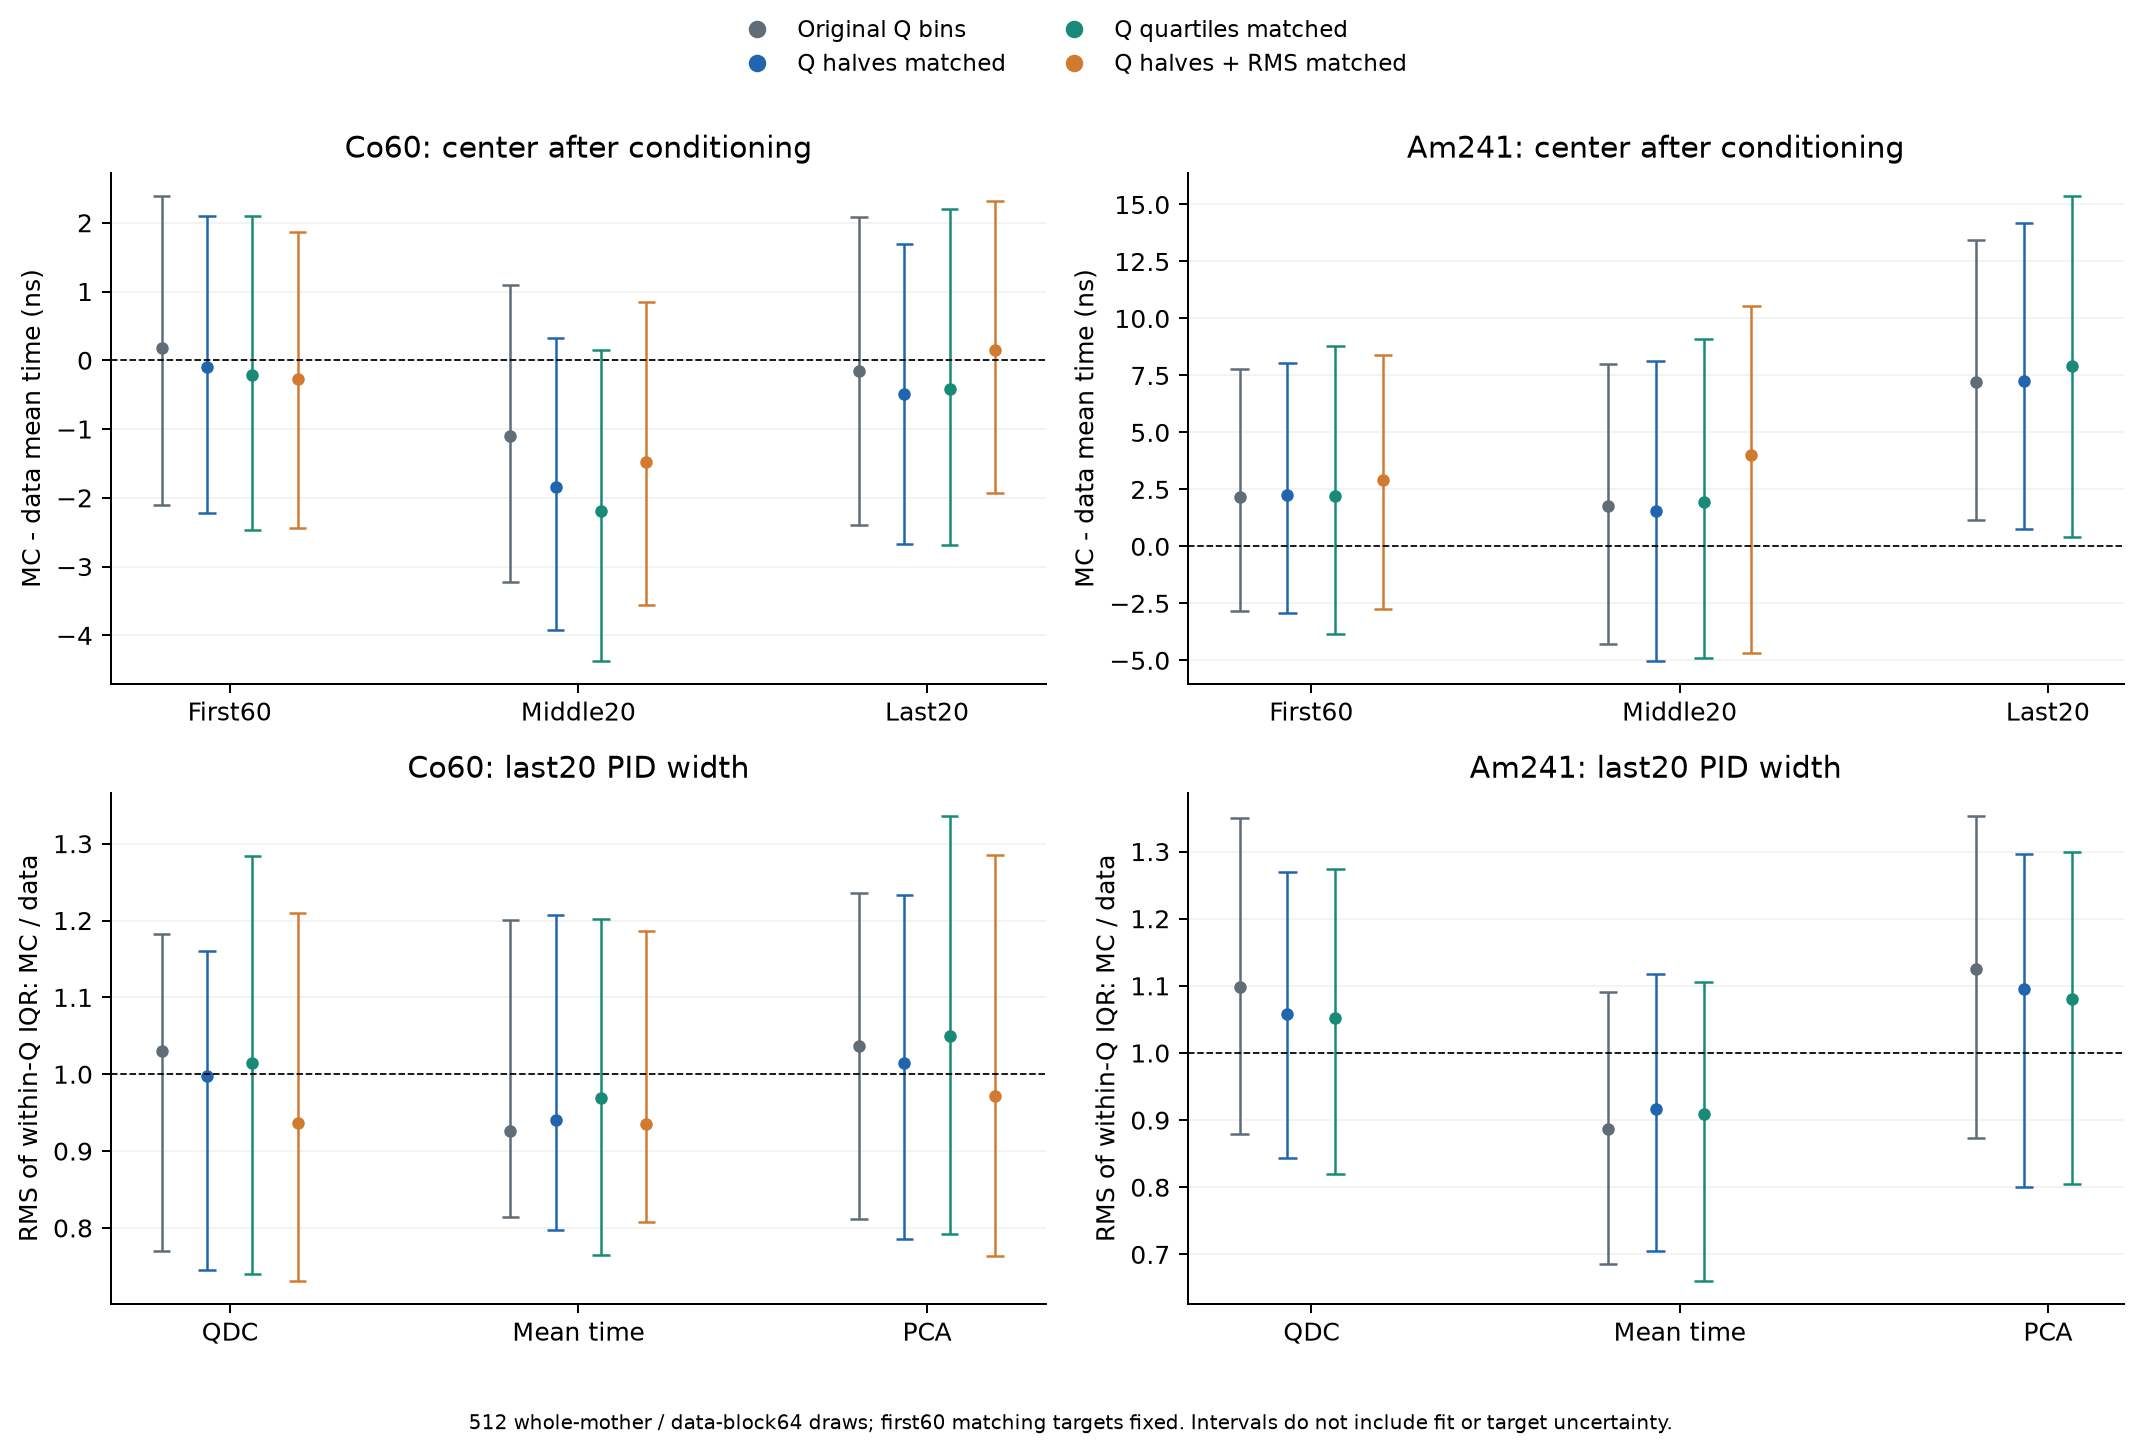

In [3]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for mode,a in c['groups'][f'run{run}_last20']['modes'].items():
        u=a['uncertainty']['64'];u128=a['uncertainty']['128']
        rows.append([source,mode,f(a['mean_time_difference_ns']),ci(u['mean_time']),nums(a['IQR_ratio']),
            ci(u['IQR_ratio'][1]),ci(u128['IQR_ratio'][1]),u['IQR_ratio'][1]['valid_draws']])
display(Markdown(table(['源/后段','权重','MC−实测平均时间/ns','块64区间/ns','QDC/时间/PCA宽度比','时间宽度比区间64','区间128','有效抽样/512'],rows)))
display(Image(filename=str(OUT/'figures/conditional_pid.png')))

Co 在不同权重下的中心和宽度差别较小。Am 后段的时间宽度比点估计从0.887变为Q两分匹配的0.917；**匹配前后变化的配对区间包含0，不能声称已确认改善**。
匹配后 Am 时间中心仍约+7.26 ns。时间宽度比区间覆盖1只说明当前精度未排除1，不是等效性证明。

Am 后段 Q×RMS 匹配在第一个原 Q 箱缺少目标单元，结果标为不可估计；没有为了获得一个数字而缩小研究对象或人为填充。
下图和表保留每箱有效样本量 ESS=(Σw)²/Σw²；Co全共同区有276条原模拟波形，Am有194条，但Am进入正式3个支持箱的只有180条。


|源|段|权重|MC最小ESS|实测最小ESS|实测支持充分|时间宽度比相对原权重变化区间|
|---|---|---|---|---|---|---|
|Co60|first60|q2|38.9|77.0|True|[-0.080, 0.083]|
|Co60|first60|q4|34.9|77.0|True|[-0.101, 0.148]|
|Co60|first60|q2r2|35.5|77.0|True|[-0.158, 0.062]|
|Co60|last20|q2|38.9|28.0|True|[-0.084, 0.102]|
|Co60|last20|q4|34.9|23.1|True|[-0.172, 0.155]|
|Co60|last20|q2r2|35.5|24.0|True|[-0.152, 0.131]|
|Am241|first60|q2|37.8|232.0|True|[-0.066, 0.133]|
|Am241|first60|q4|32.7|232.0|True|[-0.119, 0.162]|
|Am241|first60|q2r2|37.3|232.0|True|[-0.113, 0.138]|
|Am241|last20|q2|37.8|63.0|True|[-0.068, 0.115]|
|Am241|last20|q4|32.7|60.8|True|[-0.128, 0.135]|
|Am241|last20|q2r2|37.3|不可估计|False|不可估计|

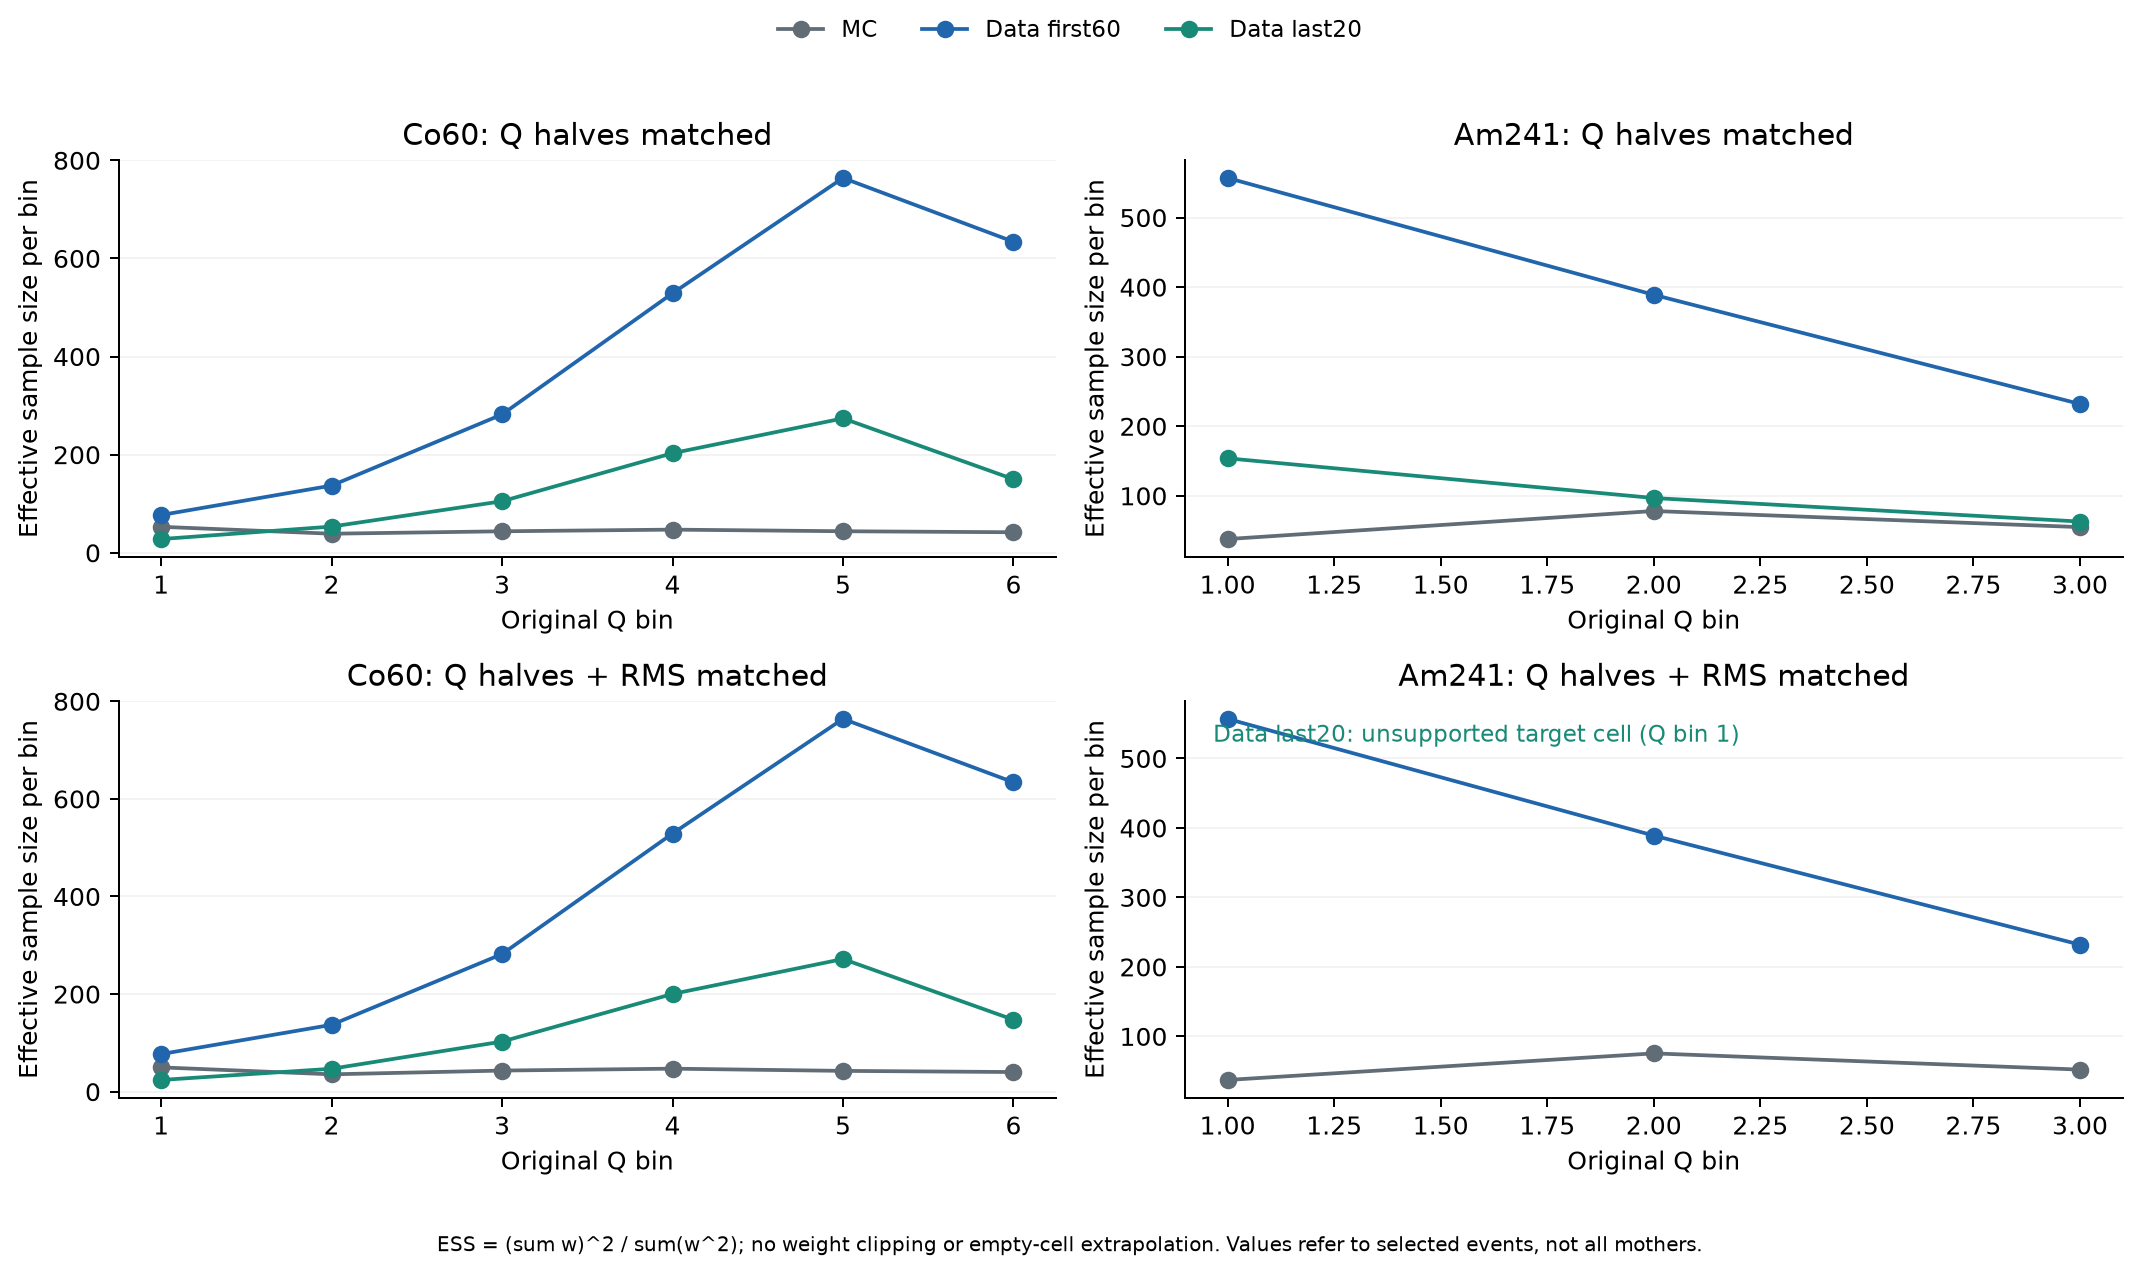

In [4]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for segment in ['first60','last20']:
        for mode in ['q2','q4','q2r2']:
            a=c['groups'][f'run{run}_{segment}']['modes'][mode]
            rows.append([source,segment,mode,f(a['MC_support'].get('minimum_ESS'),1),
                f(a['data_support'].get('minimum_ESS'),1),a['data_support']['valid'],
                ci(a['uncertainty']['64']['paired_change_from_original'][2])])
display(Markdown(table(['源','段','权重','MC最小ESS','实测最小ESS','实测支持充分','时间宽度比相对原权重变化区间'],rows)))
display(Image(filename=str(OUT/'figures/conditional_support.png')))

## 3. 采集段变化是否由箱内电荷分布解释

这里仅比较实测后段相对前段，不含 MC，不将变化归因于某个器件机制。
Q两分匹配后 Am 后段平均时间仍提前约5.02 ns：块64区间略不含0，块128包含0；Q四分的点估计为−5.70 ns，两个块长的区间均不含0。
这些是已探索样本上的多项描述性诊断，显示段差异并未随更细Q匹配消失；不能据此确定温漂、电路漂移、选择效应或闪烁过程哪个占主导。


In [5]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for mode in ['original','q2','q4']:
        r=s['data_segment_changes'][f'run{run}_last20__{mode}']
        rows.append([source,mode,f(r['data_later_minus_first60_mean_time_ns']),ci(r['uncertainty']['64']),ci(r['uncertainty']['128'])])
display(Markdown(table(['源','权重','实测后段−前段平均时间/ns','块64区间','块128区间'],rows)))

|源|权重|实测后段−前段平均时间/ns|块64区间|块128区间|
|---|---|---|---|---|
|Co60|original|0.332|[-1.346, 1.881]|[-1.011, 2.085]|
|Co60|q2|0.395|[-1.349, 1.918]|[-0.949, 2.187]|
|Co60|q4|0.198|[-1.810, 1.659]|[-1.368, 1.331]|
|Am241|original|-5.062|[-10.199, -0.087]|[-10.160, 0.290]|
|Am241|q2|-5.017|[-9.738, -0.198]|[-9.837, 0.329]|
|Am241|q4|-5.705|[-10.202, -1.041]|[-9.904, -0.557]|

## 4. 原生后脉冲/恢复机制与事件选择分开检查

所有机制效应都相对于 `no_signal_residual`，并采用同一 first60 Q两分目标。512次完整原母事件重采样在所有组之间配对。

- **固定原ID/Q**：保留原来入选的母事件与原 Q 分箱，但使用新 ADC 自身的t₁₀；这是主要机制对照。
- **重新筛选/自身Q**：重新跑完整质量与电荷选择，揭示选择迁移的共同影响。
- **固定原ID/Q/锚点**：另用原整数锚点算PID，检查对齐变化的贡献。

相同记录不重复增加样本量。固定ID结果即使新Q移出原窗也保留；重新筛选结果则按新Q判断。三组回答不同问题，不能挑最接近实验的一组作为验证成功。


|源|对照|平均时间变化/ns|配对区间/ns|QDC/时间/PCA宽度相对残差关闭|时间宽度比配对区间|
|---|---|---|---|---|---|
|Co60|identity|-0.332|[-1.401, 0.618]|1.208 / 1.082 / 1.223|[0.993, 1.385]|
|Co60|no_signal_residual|-0.000|[-0.000, 0.000]|1.000 / 1.000 / 1.000|[1.000, 1.000]|
|Co60|ap05_60ns|2.076|[1.861, 2.279]|1.003 / 0.979 / 1.022|[0.933, 1.097]|
|Co60|ap05_300ns|13.651|[13.354, 14.004]|0.978 / 0.926 / 0.962|[0.893, 1.096]|
|Co60|ap15_300ns|44.235|[43.573, 44.834]|1.027 / 1.085 / 0.990|[0.945, 1.247]|
|Co60|recovery60ns|0.723|[0.652, 0.803]|1.019 / 0.992 / 0.993|[0.978, 1.040]|
|Am241|identity|-0.426|[-5.364, 4.084]|2.215 / 2.356 / 2.497|[1.677, 3.132]|
|Am241|no_signal_residual|-0.000|[-0.000, 0.000]|1.000 / 1.000 / 1.000|[1.000, 1.000]|
|Am241|ap05_60ns|1.709|[1.312, 2.116]|0.933 / 0.984 / 0.956|[0.908, 1.137]|
|Am241|ap05_300ns|10.497|[9.946, 11.001]|0.965 / 1.056 / 0.901|[0.930, 1.188]|
|Am241|ap15_300ns|34.961|[34.116, 35.810]|0.995 / 1.036 / 0.989|[0.872, 1.245]|
|Am241|recovery60ns|0.376|[0.327, 0.430]|0.994 / 0.998 / 0.996|[0.975, 1.025]|

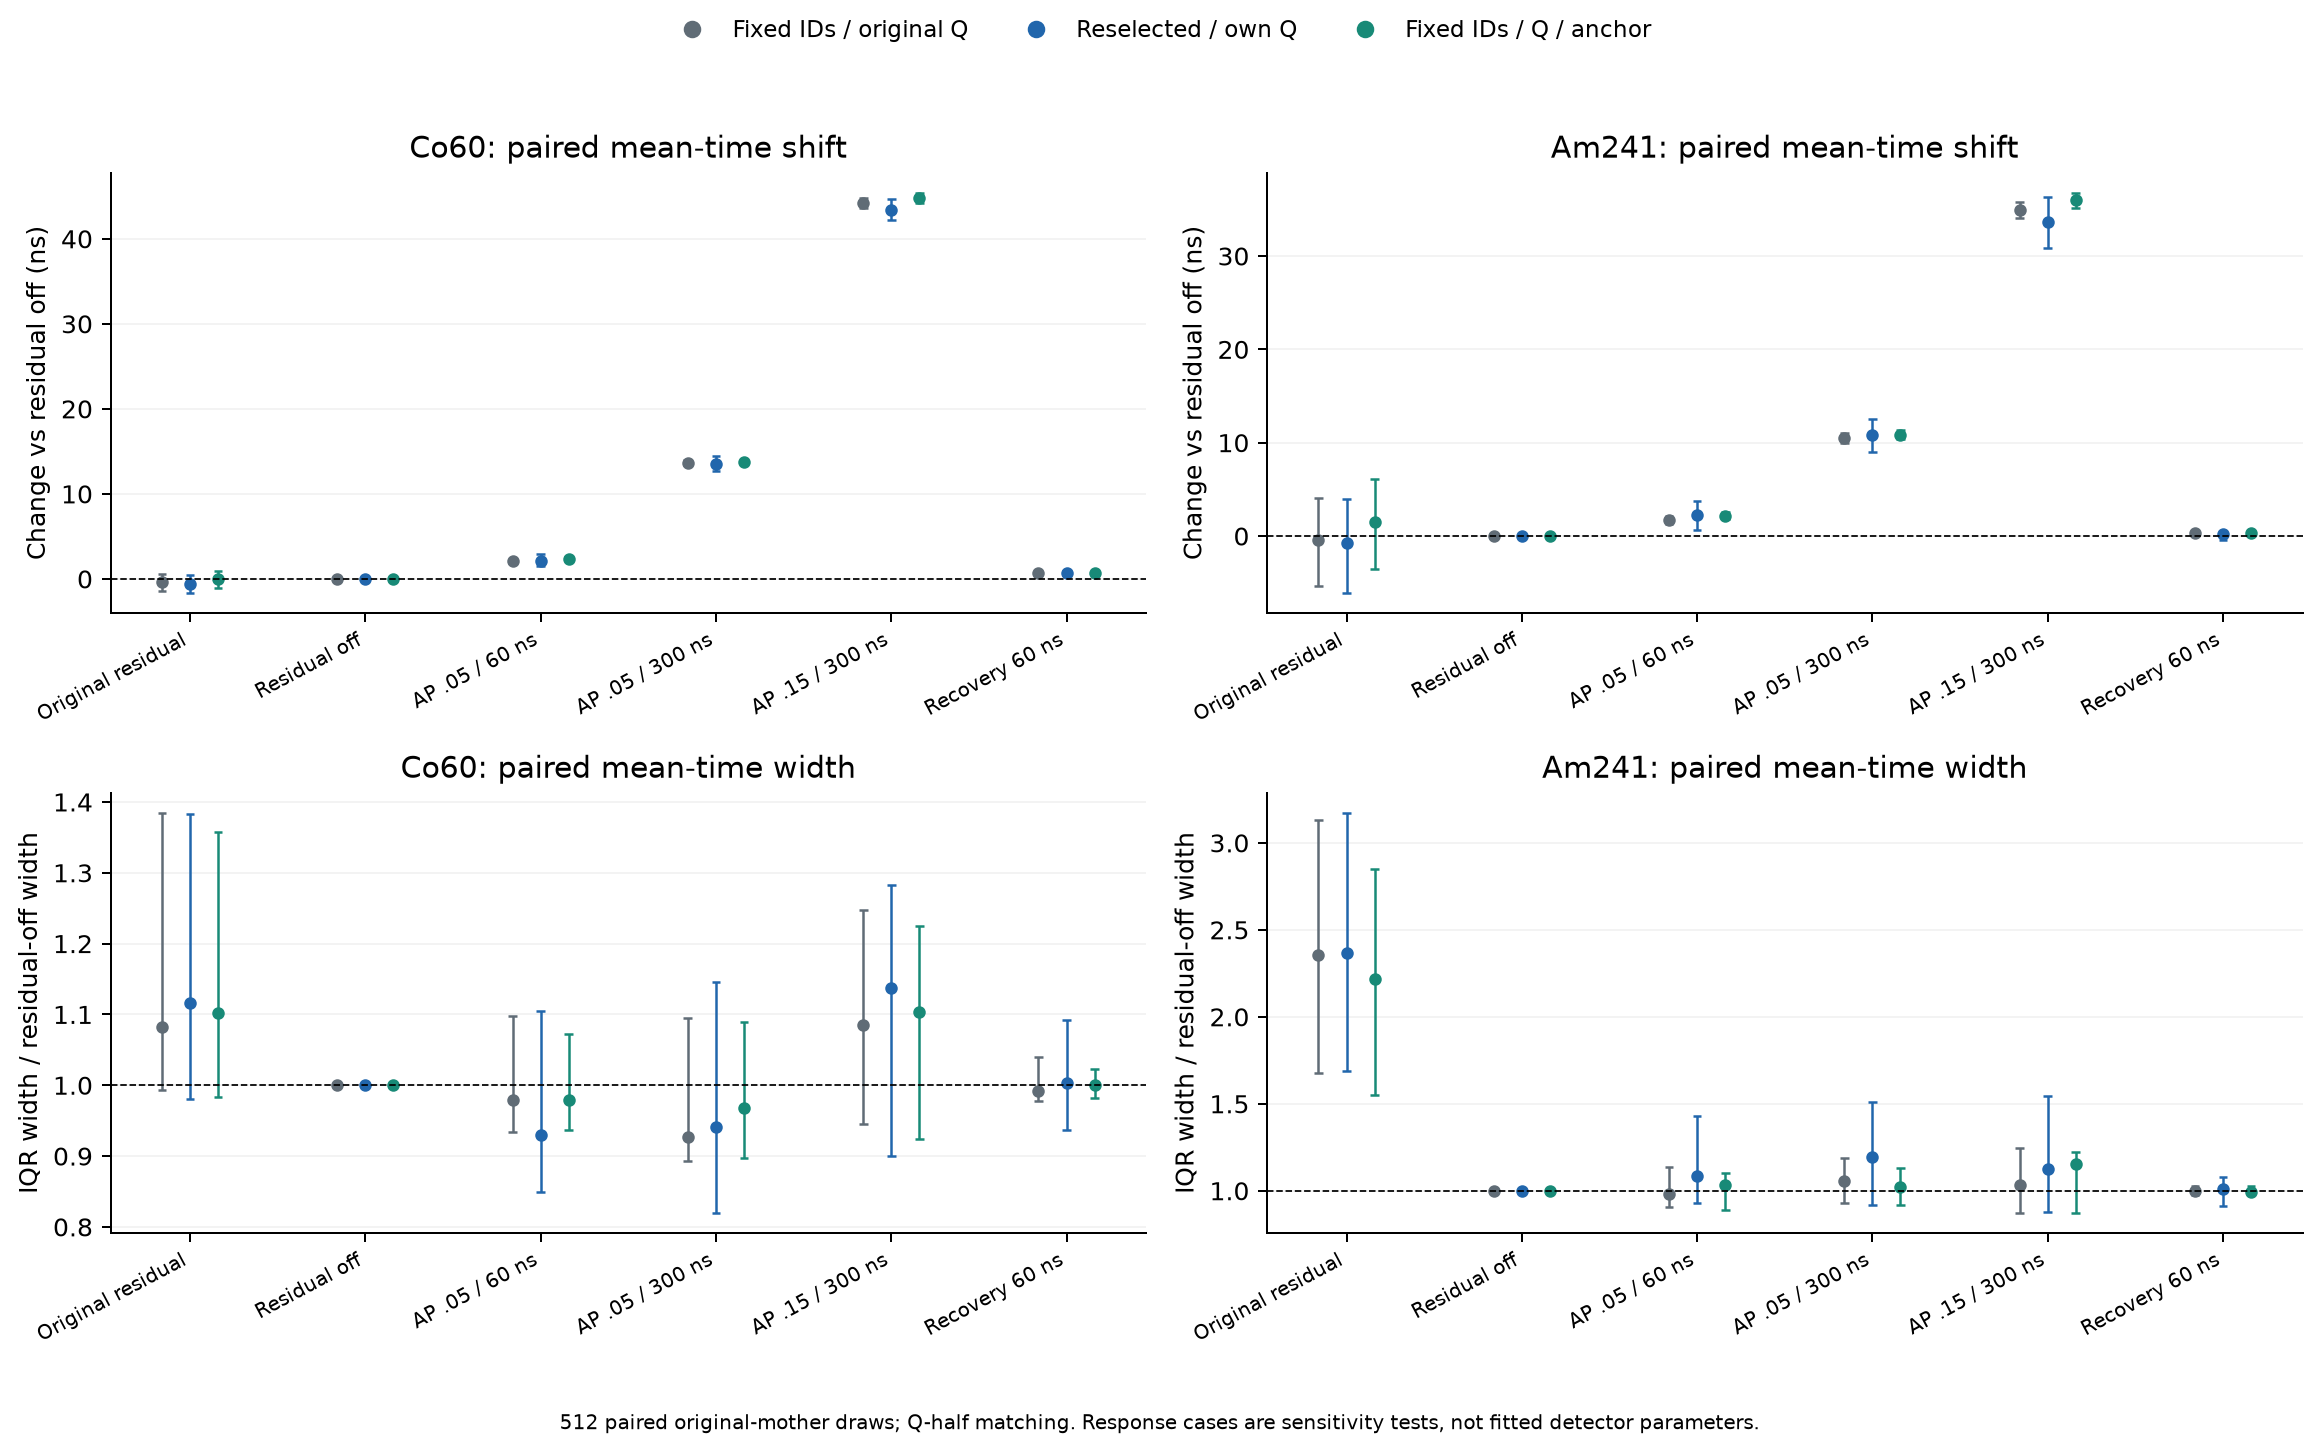

In [6]:
rows=[]
for source,z in m['sources'].items():
    for variant,r in z['variants'].items():
        a=r['schemes']['fixed'];delta=a['change_from_no_residual'];u=a['paired_effect_CI95']
        rows.append([source,variant,f(delta[0]),ci(u[0]),nums(delta[1:]),ci(u[2])])
display(Markdown(table(['源','对照','平均时间变化/ns','配对区间/ns','QDC/时间/PCA宽度相对残差关闭','时间宽度比配对区间'],rows)))
display(Image(filename=str(OUT/'figures/native_response_effects.png')))

## 5. 实际雪崩计数、平均波形与短尺度起伏

下表后脉冲占比和恢复指标直接来自原生 C++ 雪崩结果。计数以全部固定原共同Q事件汇总（Co276、Am194）；而PID统计只在支持箱内进行（Am180），两者范围不同。
平均恢复值是每事件雪崩平均恢复系数再按事件等权平均；“恢复<0.99”比例与AP比例按雪崩数汇总。还核对了 Σ各类雪崩计数=总雪崩数，以及平均恢复×雪崩数×增益×元电荷=总电荷。

波形图使用固定原ID/Q、Q两分匹配的原生 ADC 均值，没有单事件幅度缩放。F50/F102/F202为中心盒平滑后的信号期减前触发残差方差除以均信号，**不是光子或SiPM增益的Fano因子测量**。
图中的均波形/F对照与first60相比，仅列描述性点估计；不以其进行本轮拟合或模型排名。


|源|对照|实际AP占比/%|事件平均恢复|恢复<0.99雪崩/%|新Q/原Q|均ADC NRMSE/%|F50/102/202比|
|---|---|---|---|---|---|---|---|
|Co60|identity|0.000|0.99870|0.769|1.0000|1.362|0.994 / 0.995 / 0.971|
|Co60|no_signal_residual|0.000|0.99870|0.769|1.0014|1.360|0.026 / 0.100 / 0.231|
|Co60|ap05_60ns|3.735|0.99046|3.954|1.0315|1.802|0.025 / 0.098 / 0.229|
|Co60|ap05_300ns|4.676|0.99609|2.254|1.0471|1.944|0.026 / 0.100 / 0.228|
|Co60|ap15_300ns|13.870|0.99109|5.139|1.1511|5.285|0.028 / 0.101 / 0.227|
|Co60|recovery60ns|0.000|0.99762|1.320|0.9988|1.354|0.025 / 0.099 / 0.231|
|Am241|identity|0.000|0.99945|0.352|1.0000|0.908|1.014 / 0.992 / 0.979|
|Am241|no_signal_residual|0.000|0.99945|0.352|0.9987|1.100|0.017 / 0.043 / 0.087|
|Am241|ap05_60ns|3.714|0.99128|3.529|1.0284|2.034|0.017 / 0.042 / 0.087|
|Am241|ap05_300ns|4.546|0.99692|1.803|1.0425|2.594|0.017 / 0.043 / 0.087|
|Am241|ap15_300ns|13.603|0.99179|4.766|1.1438|7.296|0.016 / 0.042 / 0.085|
|Am241|recovery60ns|0.000|0.99888|0.670|0.9974|1.088|0.017 / 0.043 / 0.087|

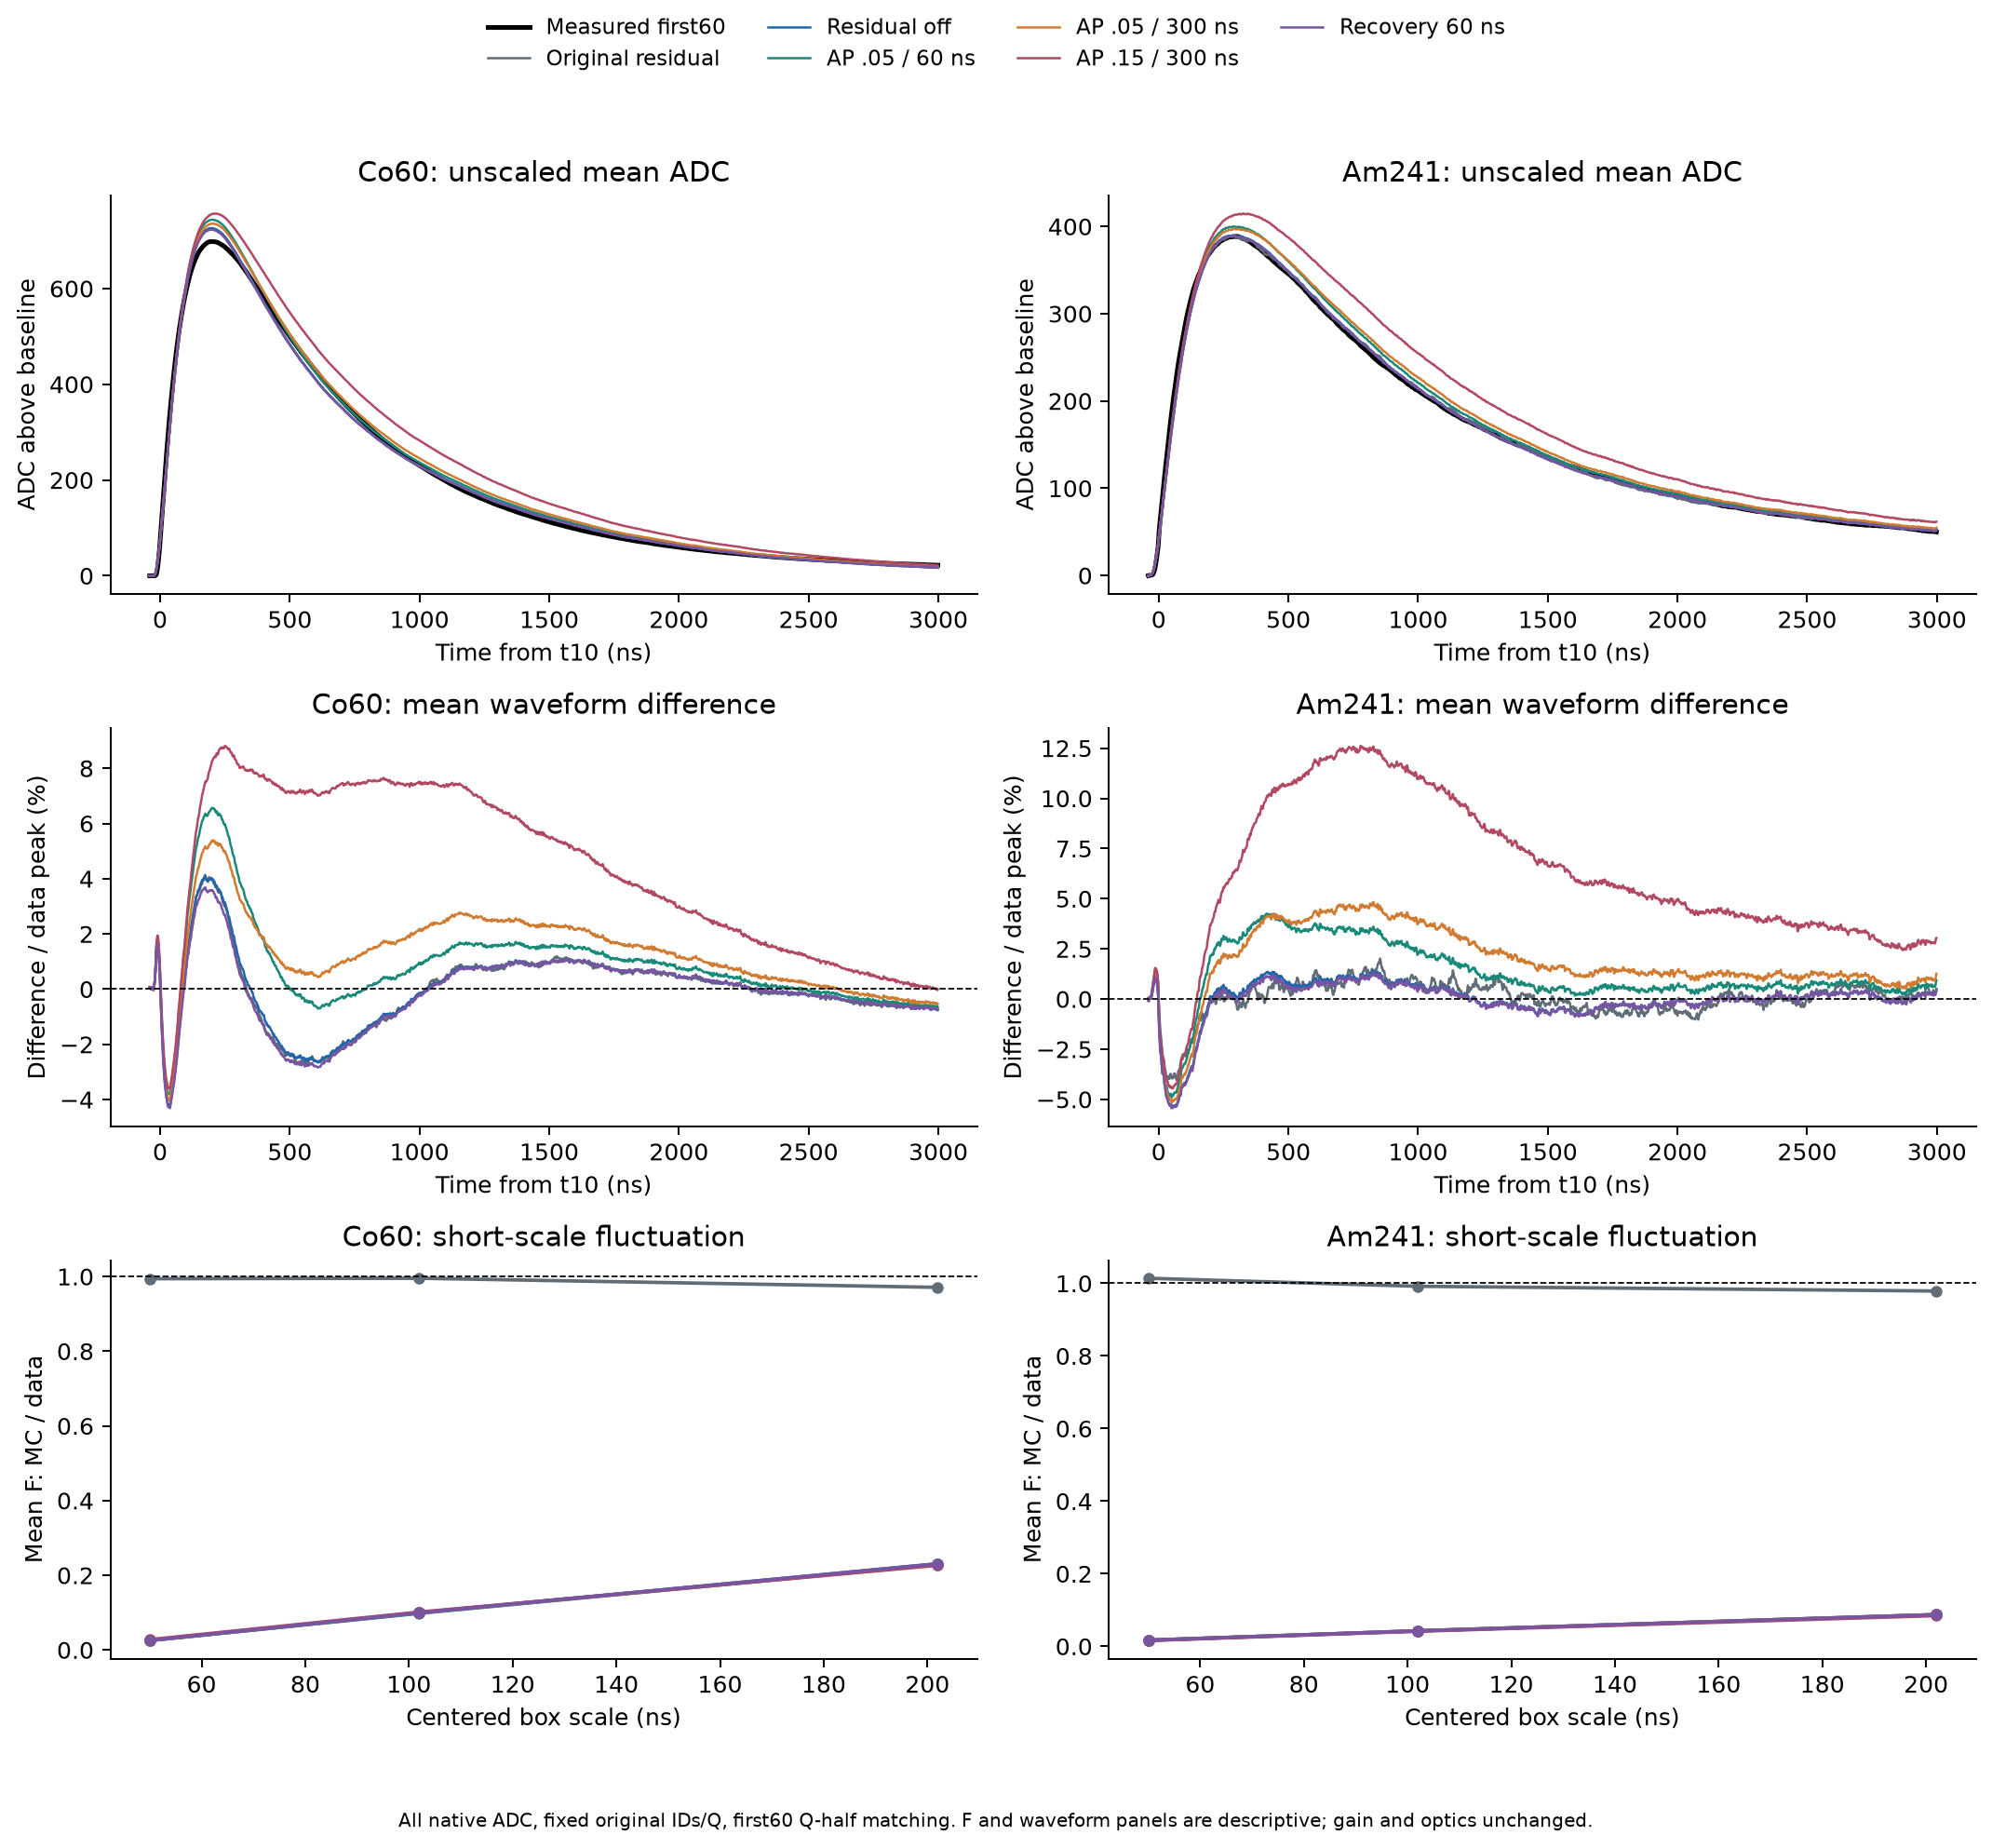

In [7]:
rows=[]
for source,z in m['sources'].items():
    for variant,r in z['variants'].items():
        e=r['extraction'];a=r['schemes']['fixed'];extra=s['waveform_checks'][source][variant]
        rows.append([source,variant,f(100*e['fixed_afterpulse_avalanche_fraction']),f(e['fixed_mean_recovery'],5),
            f(100*e['fixed_fraction_avalanches_recovery_below_099']),f(a['observed_Q_ratio_to_original'],4),
            f(100*extra['mean_ADC_NRMSE_vs_first60']),nums(extra['F_ratio_vs_first60'])])
display(Markdown(table(['源','对照','实际AP占比/%','事件平均恢复','恢复<0.99雪崩/%','新Q/原Q','均ADC NRMSE/%','F50/102/202比'],rows)))
display(Image(filename=str(OUT/'figures/native_response_waveforms.png')))

平均时间带宽只是三个PID指标之一。下面还保留完整3×3协方差变化（顺序QDC、负平均时间、PCA），以first60实测各维标准差乘积归一化。
协方差在原Q箱内按权重计算后等箱平均，采用总体分母，没有把观测协方差直接宣称为独立物理噪声分量。
原Q箱内还存有“子单元均值之间”协方差，可检查总协方差=子单元内协方差+子单元间协方差；这个统计恒等式不构成因果机制分解。


In [8]:
rows=[]
for source,z in m['sources'].items():
    for variant in ['identity','ap05_60ns','ap05_300ns','ap15_300ns','recovery60ns']:
        x=np.asarray(z['variants'][variant]['schemes']['fixed']['covariance_increment_normalized_data_SD_products'])
        rows.append([source,variant,*[f(x[i,j]) for i,j in [(0,0),(0,1),(0,2),(1,1),(1,2),(2,2)]]])
display(Markdown(table(['源','对照相对残差关闭','QQ','QT','QP','TT','TP','PP'],rows)))

|源|对照相对残差关闭|QQ|QT|QP|TT|TP|PP|
|---|---|---|---|---|---|---|---|
|Co60|identity|0.319|0.286|0.320|0.347|0.311|0.337|
|Co60|ap05_60ns|0.017|0.012|0.018|0.010|0.012|0.017|
|Co60|ap05_300ns|-0.015|-0.001|-0.012|0.019|0.003|-0.010|
|Co60|ap15_300ns|-0.015|0.040|-0.002|0.103|0.052|0.009|
|Co60|recovery60ns|0.007|0.006|0.006|0.006|0.006|0.006|
|Am241|identity|0.811|0.550|0.803|0.702|0.610|0.850|
|Am241|ap05_60ns|0.002|0.004|0.003|0.010|0.006|0.004|
|Am241|ap05_300ns|0.000|0.003|0.001|0.011|0.004|0.001|
|Am241|ap15_300ns|-0.014|0.006|-0.007|0.023|0.011|-0.002|
|Am241|recovery60ns|-0.003|-0.001|-0.003|0.000|-0.001|-0.002|

## 6. 本轮判断、下一步和复现

本轮没有寻找“最佳AP概率”，没有为新机制补偿增益或再次拟合材料时间常数。光学、无前放电路和像元模型仍存在退化；对照结果不能单独确定实际SiPM噪声率或CsI固有涨落。
继续保持原默认配置及论文主分析，既有ROC和run18结果未更新。需要补充的是模拟与已有数据的约束，而不是把其它器件或其它实验的论文成绩直接套用。


In [9]:
display(Markdown(decision['next_work_zh']))
print('默认配置替换:',decision['promoted_to_default'])
print('冻结方案:',OUT/'protocol.json')
print('实际原生命令/日志:',OUT/'execution.json')
print('12行固定事件效应表:',OUT/'mechanism_table.csv')
print('阶段顺序: prepare_conditional_response.py → run_conditional_response.py → analyze_conditional_response.py conditional / mechanisms → plot_conditional_response.py')
print('独立数值核查和归档: simulation/verify_conditional_response.py；随后 --archive')
print('构建目录:',PROJECT/'simulation/build/conditional_response_20261030')
print('四项 C++ 检查: inherited_sensor_charge_recovery_rng, stationary_readout_noise, parallel_readout_response, signal_dependent_readout_noise')

默认配置替换: False
冻结方案: /media/sf_works/SiPM/simulation/results/conditional_response_20261030/protocol.json
实际原生命令/日志: /media/sf_works/SiPM/simulation/results/conditional_response_20261030/execution.json
12行固定事件效应表: /media/sf_works/SiPM/simulation/results/conditional_response_20261030/mechanism_table.csv
阶段顺序: prepare_conditional_response.py → run_conditional_response.py → analyze_conditional_response.py conditional / mechanisms → plot_conditional_response.py
独立数值核查和归档: simulation/verify_conditional_response.py；随后 --archive
构建目录: /media/sf_works/SiPM/simulation/build/conditional_response_20261030
四项 C++ 检查: inherited_sensor_charge_recovery_rng, stationary_readout_noise, parallel_readout_response, signal_dependent_readout_noise


1. **先检查 Am 的采集段状态与信号形状。** 用原始事件顺序、前触发均值/RMS/相关谱建立状态描述；在每段有实际支持的Q区间，比较均值已去除后的信号协方差、早晚积分份额和平均时间。不跨缺失的Q×RMS单元外推，也不把信号残差拟合解释成温度测量。
2. **在first60内约束所缺的相关波动。** 比较保留光子/SIPM统计后剩余协方差的时间结构，再判断是需要随采集状态变化的读出响应，还是事件间快慢分量起伏的候选模型。这些目前都是待检验假设，均需同时约束平均波形、三种PID协方差和F，而不是只调整单个带宽。
3. **模型冻结后才增加独立模拟统计。** 目前支持箱仅有Co276、Am180条MC波形，应先按目标区间精度规划新种子完整Geant4输运量；既有重放不增加独立样本。后续再做同读出状态的α/γ真值PID检查，不能用放射源标签代替实验真值。